In [225]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [226]:
np.random.seed(42)
torch.manual_seed(42)

In [227]:
data = pd.read_csv('framingham.csv')

In [228]:
data.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [229]:
data.tail()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
4233,1,50,1.0,1,1.0,0.0,0,1,0,313.0,179.0,92.0,25.97,66.0,86.0,1
4234,1,51,3.0,1,43.0,0.0,0,0,0,207.0,126.5,80.0,19.71,65.0,68.0,0
4235,0,48,2.0,1,20.0,NaN,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,NaN,0
4237,0,52,2.0,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0


In [230]:
data.sample(5)

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
3188,1,63,1.0,0,0.0,0.0,0,1,0,190.0,148.0,90.0,27.13,72.0,86.0,0
764,1,45,3.0,0,0.0,0.0,0,0,0,162.0,125.0,89.0,27.98,85.0,83.0,0
3264,0,51,1.0,1,2.0,0.0,0,0,0,261.0,127.0,81.0,20.24,75.0,96.0,0
1967,1,45,3.0,1,30.0,0.0,0,0,0,250.0,126.0,89.5,28.68,75.0,92.0,0
2185,0,45,2.0,1,3.0,0.0,0,0,0,250.0,130.0,80.0,20.24,90.0,86.0,0


In [231]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


In [232]:
data.describe()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4238.000000,4238.000000,4133.000000,4238.000000,4209.000000,4185.000000,4238.000000,4238.000000,4238.000000,4188.000000,4238.000000,4238.000000,4219.000000,4237.000000,3850.000000,4238.000000
mean,0.429212,49.584946,1.978950,0.494101,9.003089,0.029630,0.005899,0.310524,0.025720,236.721585,132.352407,82.893464,25.802008,75.878924,81.966753,0.151958
std,0.495022,8.572160,1.019791,0.500024,11.920094,0.169584,0.076587,0.462763,0.158316,44.590334,22.038097,11.910850,4.080111,12.026596,23.959998,0.359023
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,89.875000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


In [233]:
data.isnull().sum()

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

In [234]:
data = data.replace('NA', np.nan)
numeric_columns = [
    'education',
    'cigsPerDay',
    'BPMeds',
    'totChol',
    'BMI',
    'heartRate',
    'glucose'
]

for col in numeric_columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')
data.isnull().sum()

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

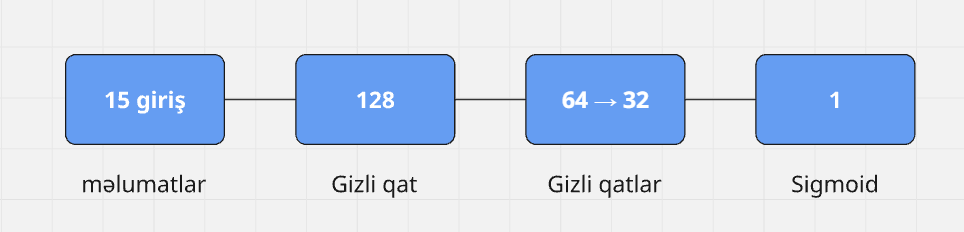

In [235]:
X = data.drop('TenYearCHD', axis=1)
y = data['TenYearCHD']

X = X.values.astype(np.float32)
y = y.values.astype(np.float32)

In [236]:
X.shape

(4238, 15)

In [237]:
y.shape

(4238,)

In [238]:
np.sum(y == 0), np.sum(y == 1)

(np.int64(3594), np.int64(644))

In [239]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [240]:
preprocessing_pipeline = Pipeline(
    [
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

In [241]:
preprocessing_pipeline.fit(X_train)

X_train_scaled = preprocessing_pipeline.transform(X_train)
X_test_scaled = preprocessing_pipeline.transform(X_test)

In [242]:
np.isnan(X_train_scaled).sum()

np.int64(0)

In [243]:
np.isnan(X_test_scaled).sum()

np.int64(0)

In [244]:
X_train_scaled.shape, X_test_scaled.shape

((3390, 15), (848, 15))

In [245]:
for step_name, step_transformer in preprocessing_pipeline.steps:
    print(f'    - {step_name}: {type(step_transformer).__name__}')

    - imputer: SimpleImputer
    - scaler: StandardScaler


In [246]:
class HeartDiseaseDataset(Dataset):
    def __init__(self, features, labels):
        self.features = torch.FloatTensor(features)
        self.labels = torch.FloatTensor(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.features[index], self.labels[index]

In [247]:
train_dataset = HeartDiseaseDataset(X_train_scaled, y_train)
test_dataset = HeartDiseaseDataset(X_test_scaled, y_test)

In [248]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

len(train_loader), len(test_loader)

(53, 14)

In [249]:
class HeartDiseaseNet(nn.Module):
    def __init__(self, input_size):
        super(HeartDiseaseNet, self).__init__()

        self.fc1 = nn.Linear(input_size, 128)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(128, 64)
        self.relu2 = nn.ReLU()

        self.fc3 = nn.Linear(64, 32)
        self.relu3 = nn.ReLU()

        self.dropout = nn.Dropout(.3)

        self.fc4 = nn.Linear(32, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu1(x)

        x = self.fc2(x)
        x = self.relu2(x)

        x = self.fc3(x)
        x = self.relu3(x)

        x = self.dropout(x)

        x = self.fc4(x)
        x = self.sigmoid(x)

        return x

In [250]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cpu


In [251]:
input_size = X_train_scaled.shape[1]
model = HeartDiseaseNet(input_size)

In [252]:
model = model.to(device)
print(f'Model architecture: {model}')

Model architecture: HeartDiseaseNet(
  (fc1): Linear(in_features=15, out_features=128, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=64, out_features=32, bias=True)
  (relu3): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (fc4): Linear(in_features=32, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


In [253]:
n_negative = (y_train == 0).sum()
n_positive = (y_train == 1).sum()
positive_weight = float(n_negative / n_positive)

class WeightedBCELoss(nn.Module):
    def __init__(self, positive_weight):
        super().__init__()
        self.positive_weight = positive_weight
        self.bce = nn.BCELoss(reduction='none')

    def forward(self, outputs, labels):
        loss = self.bce(outputs, labels)
        weights = torch.where(
            labels == 1,
            torch.full_like(labels, self.positive_weight),
            torch.ones_like(labels),
        )
        return (loss * weights).mean()

criterion = WeightedBCELoss(positive_weight)
optimizer = optim.Adam(model.parameters(), lr=0.001)
print(f'Positive class weight: {positive_weight:.4f} ({int(n_negative)} / {int(n_positive)})')
print(f'Loss: {criterion}')
print(f'Optimizer: {optimizer}')

Positive class weight: 5.5825 (2875 / 515)
Loss: WeightedBCELoss(
  (bce): BCELoss()
)
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [254]:
num_epoch = 20
train_losses = []
train_accuracies = []

for epoch in range(num_epoch):
    model.train()

    running_loss = 0.
    correct = 0
    total = 0

    train_loop = tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epoch}')
    for batch_idx, (features, labels) in enumerate(train_loop):
        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(features)
        outputs = outputs.squeeze()

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss+= loss.item()

        predicted = (outputs>= 0.5).float()

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

        train_loop.set_postfix(
            {
                'loss': f'{loss.item():.4f}',
                'accuracy': f'{correct / total:.2f}'
            }
        )
    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(f'Epoch [{epoch+1}/{num_epoch}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.2f}%')
print('Finished Training')

Epoch 1/20: 100%|██████████| 53/53 [00:00<00:00, 278.17it/s, loss=1.0204, accuracy=0.45]


Epoch [1/20], Loss: 1.1162, Accuracy: 44.51%


Epoch 2/20: 100%|██████████| 53/53 [00:00<00:00, 275.41it/s, loss=0.8994, accuracy=0.66]


Epoch [2/20], Loss: 1.0293, Accuracy: 65.69%


Epoch 3/20: 100%|██████████| 53/53 [00:00<00:00, 251.20it/s, loss=1.0721, accuracy=0.67]


Epoch [3/20], Loss: 1.0228, Accuracy: 67.08%


... (30 outputs left out)

Epoch 19/20: 100%|██████████| 53/53 [00:00<00:00, 243.49it/s, loss=0.8601, accuracy=0.76]


Epoch [19/20], Loss: 0.8580, Accuracy: 76.37%


Epoch 20/20: 100%|██████████| 53/53 [00:00<00:00, 215.79it/s, loss=0.7399, accuracy=0.76]

Epoch [20/20], Loss: 0.8455, Accuracy: 75.99%
Finished Training


In [255]:
model.eval()

with torch.no_grad():
    test_loss = 0.
    correct = 0
    total = 0

    all_predictions = []
    all_labels = []

    test_loop = tqdm(test_loader, desc='Testing')
    for (features, labels) in test_loop:
        features = features.to(device)
        labels = labels.to(device)

        outputs = model(features)
        outputs = outputs.squeeze()

        loss = criterion(outputs, labels)
        test_loss+= loss.item()

        predicted = (outputs>= 0.5).float()

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        test_loop.set_postfix(
            {
                'loss': f'{loss.item():.4f}',
                'accuracy': f'{100* correct / total:.2f}%'
            }
        )
avg_test_loss = test_loss / len(test_loader)
test_accuracy = 100 * correct/ total

print(f'Test data results: Loss: {avg_test_loss:.4f}, Accuracy: {test_accuracy:.2f}%, True predictions: {100 * correct / total:.2f}%')

Testing: 100%|██████████| 14/14 [00:00<00:00, 484.90it/s, loss=1.1315, accuracy=67.81%]

Test data results: Loss: 1.2698, Accuracy: 67.81%, True predictions: 67.81%


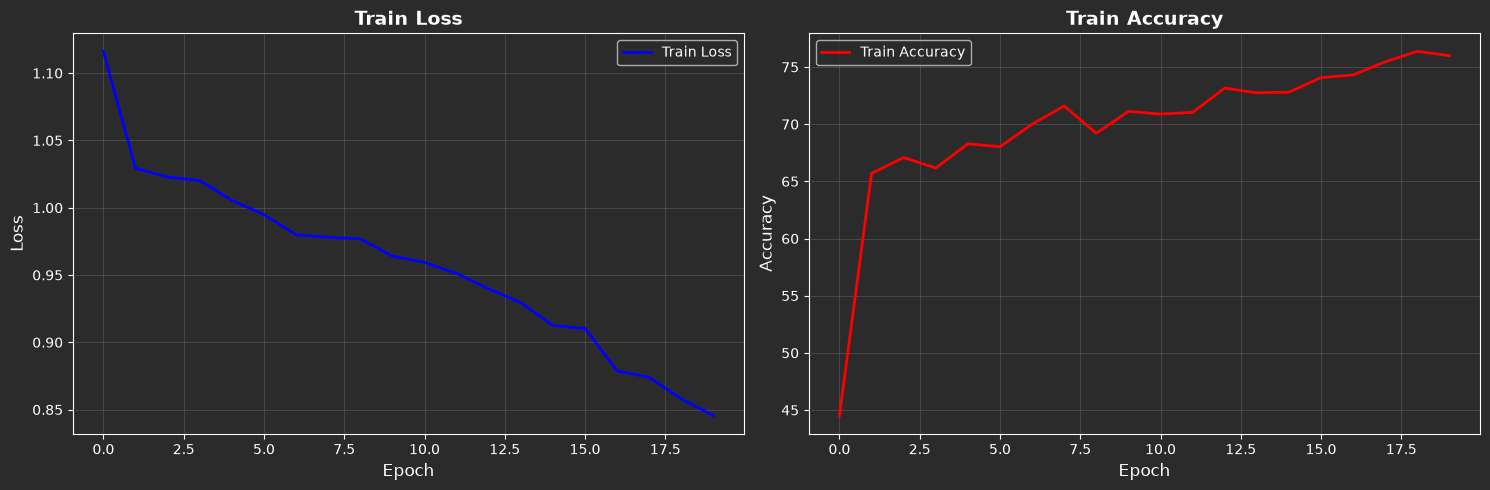

In [256]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(
    train_losses,
    label='Train Loss',
    color='blue',
    linewidth=2,
)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.set_title('Train Loss', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(
    train_accuracies,
    label='Train Accuracy',
    color='red',
    linewidth=2,
)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Accuracy', fontsize=12)
ax2.set_title('Train Accuracy', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()

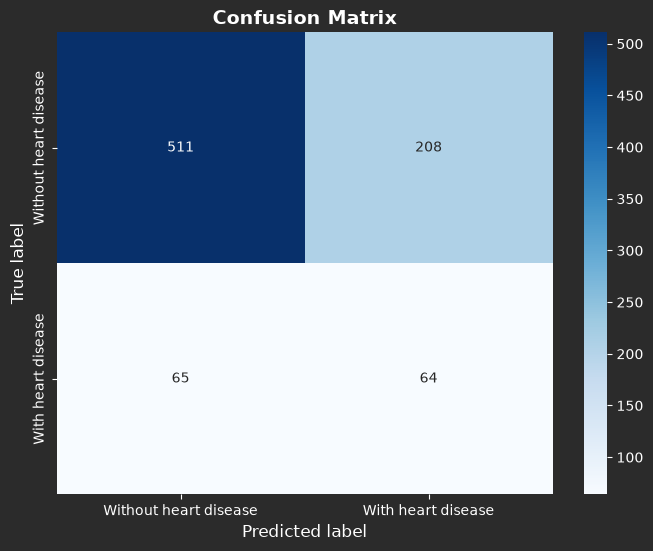

              precision    recall  f1-score   support

         0.0       0.89      0.71      0.79       719
         1.0       0.24      0.50      0.32       129

    accuracy                           0.68       848
   macro avg       0.56      0.60      0.55       848
weighted avg       0.79      0.68      0.72       848



In [257]:
all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

cm = confusion_matrix(all_labels, all_predictions, labels=[0, 1])

class_names = ["Without heart disease", "With heart disease"]

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('True label', fontsize=12)
plt.xlabel('Predicted label', fontsize=12)

plt.show()

print(classification_report(all_labels, all_predictions))

In [258]:
sample_features = {
    'male': 1,
    'age': 80,
    'education': 4,
    'currentSmoker': 1,
    'cigsPerDay': 30,
    'BPMeds':1,
    'prevalentStroke': 1,
    'prevalentHyp': 1,
    'diabetes':1,
    'totChol': 250,
    'sysBP': 170,
    'diaBP': 90,
    'BMI': 80,
    'heartRate': 80,
    'glucose': 250,
}
feature_columns = data.drop(columns='TenYearCHD').columns

sample_df = pd.DataFrame([sample_features])
sample_df = sample_df[feature_columns]


sample_features_processed = preprocessing_pipeline.transform(
    sample_df.to_numpy(dtype=np.float32)
)

sample_tensor_new = torch.FloatTensor(
    sample_features_processed
).to(device)

model.eval()

with torch.no_grad():
    prediction_new = model(sample_tensor_new)
    probability_new = prediction_new.item()

print(
    'With heart disease'
    if probability_new >= 0.5
    else 'Without heart disease'
)
print(f'{probability_new * 100:.2f}%')

With heart disease
98.92%
